In [ ]:
# @title Служебная ячейка: импорты и функции проверки { display-mode: "form" }
import inspect
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 0
rng = np.random.default_rng(SEED)


def assert_no_loops(func):
    """Проверяет, что в теле функции нет циклов for/while (включения списков тоже считаются)."""
    source = inspect.getsource(func)
    body = source.split('"""')[-1] if '"""' in source else source
    assert not re.search(r"\b(for|while)\b", body), (
        f"В функции {func.__name__} есть цикл. Здесь нужно решение без циклов — операциями над массивами."
    )


def make_blobs_data(n, d, n_classes, seed):
    """Синтетические данные для проверок: облака точек вокруг случайных центров."""
    r = np.random.default_rng(seed)
    centers = r.normal(scale=3, size=(n_classes, d))
    y = r.integers(0, n_classes, size=n)
    X = centers[y] + r.normal(size=(n, d))
    return X, y


print("Готово")

Готово


# Часть 1. kNN своими руками

Задание 1.1. Матрица расстояний

In [ ]:
from sklearn.metrics import pairwise_distances as sk_pairwise_distances

def pairwise_distances(A, B, metric="euclidean"):
    dict_metric = {
        "euclidean": lambda a, b: np.sqrt(np.sum((a[:, None, :] - b[None, :, :]) ** 2, axis=-1)),
        "manhattan": lambda a, b: np.sum(np.abs(a[:, None, :] - b[None, :, :]), axis=-1)
    }

    try:
      return dict_metric[metric](A, B)
    except KeyError:
      raise ValueError(f"Неизвестная метрика: {metric}")

A = rng.normal(size=(20, 5))
B = rng.normal(size=(7, 5))
for metric in ["euclidean", "manhattan"]:
    D = pairwise_distances(A, B, metric)
    assert D.shape == (20, 7), f"{metric}: форма должна быть (20, 7), получено {D.shape}"
    assert np.allclose(D, sk_pairwise_distances(A, B, metric=metric)), f"{metric}: расстояния не совпадают со sklearn"
assert np.allclose(np.diag(pairwise_distances(A, A)), 0, atol=1e-6), "Расстояние от точки до самой себя должно быть 0"
try:
    pairwise_distances(A, B, "cosine")
    raise AssertionError("Для неизвестной метрики должна подниматься ValueError")
except ValueError:
    pass
assert_no_loops(pairwise_distances)
print("OK")


OK


Задание 1.2. Предсказание kNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

def knn_votes(X_train, y_train, X_test, k, metric="euclidean"):
    distances = pairwise_distances(X_test, X_train, metric=metric)

    near_id = np.argsort(distances, axis=1)[:, :k]
    near_label = y_train[near_id]

    k = y_train.max() + 1
    one_hot = np.eye(k)[near_label]

    return np.sum(one_hot, axis=1)

def knn_predict(X_train, y_train, X_test, k, metric="euclidean"):
    votes = knn_votes(X_train, y_train, X_test, k, metric=metric)

    return np.argmax(votes, axis=1)

X_tr, y_tr = make_blobs_data(300, 4, 3, seed=1)
X_te, y_te = make_blobs_data(100, 4, 3, seed=2)
votes = knn_votes(X_tr, y_tr, X_te, k=5)
assert votes.shape == (100, 3), f"Матрица голосов должна иметь форму (100, 3), получено {votes.shape}"
assert np.allclose(votes.sum(axis=1), 5), "В каждой строке голосов сумма должна быть равна k"
for k in [1, 4, 15]:
    for metric in ["euclidean", "manhattan"]:
        ours = knn_predict(X_tr, y_tr, X_te, k, metric)
        sk = KNeighborsClassifier(n_neighbors=k, metric=metric, algorithm="brute").fit(X_tr, y_tr).predict(X_te)
        assert ours.shape == (100,), f"Предсказание должно иметь форму (100,), получено {ours.shape}"
        assert np.array_equal(ours, sk), f"k={k}, {metric}: предсказания расходятся со sklearn в {np.sum(ours != sk)} объектах"
assert np.array_equal(knn_predict(X_tr, y_tr, X_tr, 1), y_tr), "При k=1 на обучающей выборке ответ должен совпадать с y_train"
assert_no_loops(knn_votes)
assert_no_loops(knn_predict)
print("OK")

OK


Задание 1.3. Оценка вероятностей

In [ ]:
def knn_predict_proba(X_train, y_train, X_test, k, metric="euclidean"):

    return knn_votes(X_train, y_train, X_test, k, metric=metric) / k

P = knn_predict_proba(X_tr, y_tr, X_te, k=7)
P_sk = KNeighborsClassifier(n_neighbors=7, algorithm="brute").fit(X_tr, y_tr).predict_proba(X_te)
assert P.shape == P_sk.shape, f"Форма должна быть {P_sk.shape}, получено {P.shape}"
assert np.allclose(P.sum(axis=1), 1), "Вероятности в каждой строке должны давать в сумме 1"
assert np.allclose(P, P_sk), "Вероятности не совпадают с predict_proba из sklearn"
print("OK")


OK


Задание 1.4. Стандартизация как объект с fit и transform

In [ ]:
from sklearn.preprocessing import StandardScaler

class MyStandardScaler:
    def __init__(self):
        self.mean_ = None
        self.scale_ = None

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)
        scales = np.std(X, axis=0)

        self.scale_ = np.where(scales == 0, 1.0, scales)

        return self

    def transform(self, X):

        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

X_a = rng.normal(loc=[0, 50, 3], scale=[1, 10, 0.1], size=(100, 3))
X_a[:, 2] = 3.0  # признак-константа
X_b = rng.normal(loc=[0, 50, 3], scale=[1, 10, 0.1], size=(30, 3))
ours = MyStandardScaler()
assert ours.fit(X_a) is ours, "fit должен возвращать self"
sk = StandardScaler().fit(X_a)
assert np.allclose(ours.mean_, sk.mean_), "mean_ не совпадает со sklearn"
assert np.allclose(ours.scale_, sk.scale_), "scale_ не совпадает со sklearn (для константного столбца должно быть 1)"
assert np.allclose(ours.transform(X_b), sk.transform(X_b)), "transform новых данных не совпадает со sklearn: используйте параметры из fit"
assert not np.isnan(ours.transform(X_a)).any(), "Для константного столбца получилось деление на ноль"
assert_no_loops(MyStandardScaler.fit)
assert_no_loops(MyStandardScaler.transform)
print("OK")

OK


Задание 1.5. Кросс-валидация

In [ ]:
from sklearn.model_selection import KFold, cross_val_score

def kfold_indices(n, n_folds, seed):
    """Список из n_folds массивов индексов — как в KFold(n_folds, shuffle=True, random_state=seed)."""
    perm = np.random.RandomState(seed).permutation(n)
    return np.array_split(perm, n_folds)


def cross_val_accuracy(X, y, k, n_folds=5, seed=SEED):
    fold_id_test = kfold_indices(len(X), n_folds, seed)
    acc = []

    for i in range(n_folds):
      test_idx = fold_id_test[i]
      train_idx = np.concatenate([fold_id_test[j] for j in range(n_folds) if j != i])

      X_train, y_train = X[train_idx], y[train_idx]
      X_test, y_test = X[test_idx], y[test_idx]

      pred = knn_predict(X_train, y_train, X_test, k=k)

      fold_acc = np.mean(pred == y_test)
      acc.append(fold_acc)

    return np.mean(acc)

X_cv, y_cv = make_blobs_data(250, 3, 2, seed=3)
X_cv += rng.normal(scale=2, size=X_cv.shape)  # добавим шума, чтобы задача не была слишком простой
for k in [1, 9]:
    ours = cross_val_accuracy(X_cv, y_cv, k, n_folds=5, seed=SEED)
    sk = cross_val_score(
        KNeighborsClassifier(n_neighbors=k, algorithm="brute"), X_cv, y_cv,
        cv=KFold(5, shuffle=True, random_state=SEED),
    ).mean()
    assert np.isclose(ours, sk), f"k={k}: ваша оценка {ours:.4f}, sklearn — {sk:.4f}"
print("OK")

OK


Задание 1.6. Точность, полнота, F-мера

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score

def precision_recall_f1(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    return float(precision), float(recall), float(f1)

for trial in range(5):
    t = rng.integers(0, 2, size=50)
    p = rng.integers(0, 2, size=50)
    expected = (precision_score(t, p), recall_score(t, p), f1_score(t, p))
    assert np.allclose(precision_recall_f1(t, p), expected), f"Метрики не совпадают со sklearn: ожидалось {expected}"
t = np.array([1, 0, 1, 0])
assert precision_recall_f1(t, np.array([0, 1, 1, 0])) == (0.5, 0.5, 0.5), "Для TP=1, FP=1, FN=1 ожидается (0.5, 0.5, 0.5)"
assert precision_recall_f1(t, np.zeros(4, dtype=int)) == (0.0, 0.0, 0.0), "Если положительных предсказаний нет, все метрики равны 0"
assert_no_loops(precision_recall_f1)
print("OK")

OK


# Часть 2. kNN в scikit-learn: Зал славы бейсбола

In [ ]:
# @title Загрузка данных: Baseball Hall of Fame (OpenML, id 185) { display-mode: "form" }
from sklearn.datasets import fetch_openml

baseball = fetch_openml(data_id=185, as_frame=True, parser="auto").frame
y_all = (baseball["Hall_of_Fame"].astype(str) != "0").astype(int).to_numpy()
X_all = baseball.drop(columns=["Hall_of_Fame"])
NUMERIC = [c for c in X_all.columns if c != "Position"]
CATEGORICAL = ["Position"]
print(f"Объектов: {len(X_all)}, признаков: {X_all.shape[1]}, доля класса 1: {y_all.mean():.3f}")
X_all.describe().T[["mean", "std", "min", "max"]]

Объектов: 1340, признаков: 16, доля класса 1: 0.093


,mean,std,min,max
Number_seasons,13.485821,3.136279,10.000,26.000
Games_played,1331.263433,519.165125,140.000,3562.000
At_bats,4534.612687,2094.191124,252.000,14053.000
Runs,635.313433,376.400804,20.000,2246.000
Hits,1248.567164,647.664709,48.000,4256.000
Doubles,203.225373,116.576053,6.000,792.000
Triples,50.811940,41.038358,0.000,309.000
Home_runs,85.109701,97.930043,0.000,755.000
RBIs,565.744776,357.163666,21.000,2297.000
Walks,445.584328,295.214016,17.000,2056.000


Задание 2.1. Разбиение на обучающую и тестовую выборки

In [ ]:
from sklearn.model_selection import train_test_split

X_train, x_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.25,
    random_state=SEED,
    stratify=y_all
)

assert len(X_test) == 335 and len(X_train) == 1005, f"Ожидалось 1005 объектов в обучении и 335 в тесте, получено {len(X_train)} и {len(X_test)}"
assert set(X_train.index).isdisjoint(X_test.index), "Обучающая и тестовая выборки пересекаются"
assert y_test.sum() == 31 and y_train.sum() == 94, (
    f"В тест должно попасть 31 из 125 членов Зала славы (стратификация), попало {y_test.sum()}: проверьте stratify=y_all"
)
print(f"OK: доля класса 1 в обучении {y_train.mean():.3f}, в тесте {y_test.mean():.3f}")

OK: доля класса 1 в обучении 0.094, в тесте 0.093


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"accuracy = {accuracy_score(y_test, dummy.predict(X_test)):.3f}, "
      f"F1 = {f1_score(y_test, dummy.predict(X_test)):.3f}")

accuracy = 0.907, F1 = 0.000


Задание 2.2. Конвейер

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.compose import make_column_selector

def make_model(scale=True):
    if scale:
      numeric = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        )
    else:
      numeric = SimpleImputer(strategy="median")

    category = OneHotEncoder(handle_unknown="ingore")
    preprocess = ColumnTransformer(
        transformers=[
            ('num', numeric, make_column_selector(dtype_include="number")),
            ('cat', category, make_column_selector(dtype_include="object"))
        ]
    )

    model = Pipeline([
        ('preprocessor', preprocess),
        ('knn', KNeighborsClassifier())
    ])

    return model

def _contains(estimator, cls):
    return cls.__name__ in repr(estimator)

for scale in [True, False]:
    model = make_model(scale)
    assert isinstance(model, Pipeline), "make_model должна возвращать Pipeline"
    assert isinstance(model.steps[-1][1], KNeighborsClassifier), "Последний шаг конвейера — KNeighborsClassifier"
    assert _contains(model, StandardScaler) == scale, f"При scale={scale} StandardScaler {'должен' if scale else 'не должен'} быть в конвейере"
    assert _contains(model, SimpleImputer) and _contains(model, OneHotEncoder), "В конвейере нужны SimpleImputer и OneHotEncoder"
    pred = model.fit(X_train, y_train).predict(X_test)
    assert pred.shape == (len(X_test),), "Конвейер должен обучаться на X_train и предсказывать для X_test"
print("OK")

OK


Задание 2.3. Подбор гиперпараметров

In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

PARAM_GRID = {"knn__n_neighbors": list(range(1, 52, 2)), "knn__weights": ["uniform", "distance"]}
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)

grid_scaled = GridSearchCV(
    estimator=make_model(scale=True),
    param_grid=PARAM_GRID,
    scoring="f1",
    cv=CV
)
grid_scaled.fit(X_train, y_train)

grid_raw = GridSearchCV(
    estimator=make_model(scale=False),
    param_grid=PARAM_GRID,
    scoring="f1",
    cv=CV
)
grid_raw.fit(X_train, y_train)

print("с масштабированием:", grid_scaled.best_params_, f"F1 (CV) = {grid_scaled.best_score_:.3f}")
print("без масштабирования:", grid_raw.best_params_, f"F1 (CV) = {grid_raw.best_score_:.3f}")

for name, grid in [("grid_scaled", grid_scaled), ("grid_raw", grid_raw)]:
    assert isinstance(grid, GridSearchCV), f"{name} должен быть GridSearchCV"
    assert grid.scoring == "f1", f"{name}: метрика должна быть f1"
    assert len(grid.cv_results_["params"]) == 52, f"{name}: в сетке должно быть 26 значений k × 2 способа взвешивания"
    assert grid.n_splits_ == 5, f"{name}: нужна 5-кратная кросс-валидация"
    assert hasattr(grid, "best_estimator_"), f"{name}: поиск не обучен"
assert _contains(grid_scaled.best_estimator_, StandardScaler), "grid_scaled должен использовать make_model(scale=True)"
assert not _contains(grid_raw.best_estimator_, StandardScaler), "grid_raw должен использовать make_model(scale=False)"
assert grid_scaled.best_score_ > grid_raw.best_score_, "С масштабированием F1 на кросс-валидации должна быть выше — проверьте конвейеры"
print("OK")

с масштабированием: {'knn__n_neighbors': 9, 'knn__weights': 'uniform'} F1 (CV) = 0.671
без масштабирования: {'knn__n_neighbors': 5, 'knn__weights': 'uniform'} F1 (CV) = 0.611
OK


Задание 2.4. Итоговая оценка на тестовой выборке

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.metrics import accuracy_score, f1_score

best = grid_scaled.best_estimator_

y_pred = best.predict(X_test)
y_pred_proba = best.predict_proba(X_test)[:, 1]

test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_pred_proba)
}

print(pd.Series(test_metrics).round(3))
print("Матрица ошибок (строки — истинный класс, столбцы — предсказанный):")
print(confusion_matrix(y_test, best.predict(X_test)))


assert set(test_metrics) == {"accuracy", "precision", "recall", "f1", "roc_auc"}, f"Нужны ключи accuracy, precision, recall, f1, roc_auc; получено {set(test_metrics)}"
_pred = best.predict(X_test)
assert np.isclose(test_metrics["f1"], f1_score(y_test, _pred)), "f1 посчитана неверно"
assert np.isclose(test_metrics["recall"], recall_score(y_test, _pred)), "recall посчитан неверно"
assert np.isclose(test_metrics["roc_auc"], roc_auc_score(y_test, best.predict_proba(X_test)[:, 1])), (
    "roc_auc посчитан неверно: для него нужны вероятности predict_proba(X_test)[:, 1], а не предсказанные классы"
)
print("OK")

accuracy     0.952
precision    0.941
recall       0.516
f1           0.667
roc_auc      0.903
dtype: float64
Матрица ошибок (строки — истинный класс, столбцы — предсказанный):
[[303   1]
 [ 15  16]]
OK


# Часть 3. Эксперимент и выводы

Задание 3.1. Качество в зависимости от k

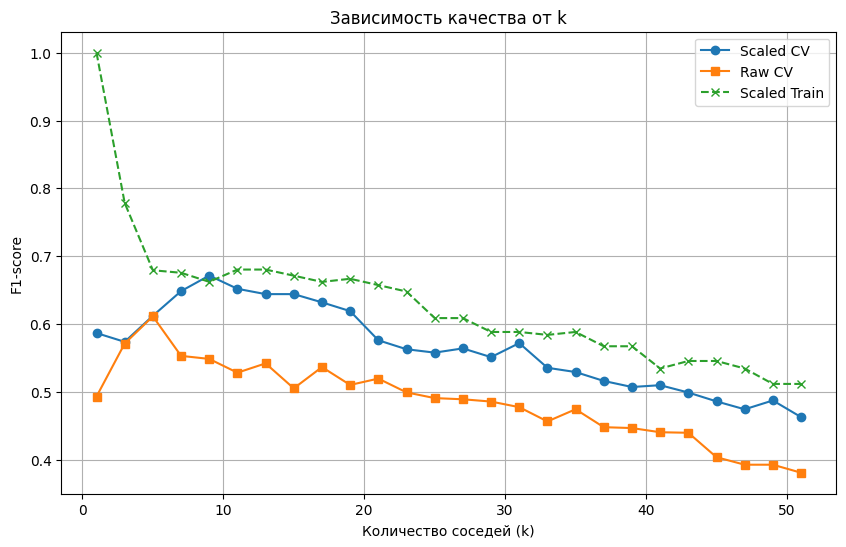

OK


In [ ]:
import matplotlib.pyplot as plt

K_VALUES = list(range(1, 52, 2))

df_scaled = pd.DataFrame(grid_scaled.cv_results_)
df_raw = pd.DataFrame(grid_raw.cv_results_)

df_scaled_uni = df_scaled[df_scaled['param_knn__weights'] == 'uniform'].sort_values('param_knn__n_neighbors')
df_raw_uni = df_raw[df_raw['param_knn__weights'] == 'uniform'].sort_values('param_knn__n_neighbors')

train_f1 = []
for k in K_VALUES:
    model = make_model(scale=True)
    model.set_params(knn__n_neighbors=k, knn__weights='uniform')

    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)

    train_f1.append(f1_score(y_train, pred_train))

plt.figure(figsize=(10, 6))

plt.plot(df_scaled_uni['param_knn__n_neighbors'], df_scaled_uni['mean_test_score'],
         label='Scaled CV', marker='o')

plt.plot(df_raw_uni['param_knn__n_neighbors'], df_raw_uni['mean_test_score'],
         label='Raw CV', marker='s')

plt.plot(K_VALUES, train_f1, label='Scaled Train', linestyle='--', marker='x')

plt.xlabel('Количество соседей (k)')
plt.ylabel('F1-score')
plt.title('Зависимость качества от k')
plt.grid(True)
plt.legend()
plt.show()

assert len(train_f1) == len(K_VALUES), f"train_f1 должен содержать {len(K_VALUES)} значений — по одному на каждое k"
assert np.isclose(train_f1[0], 1.0), "При k=1 F1 на обучающей выборке должна быть равна 1: каждый объект — сам себе ближайший сосед"
assert train_f1[-1] < train_f1[0], "При k=51 F1 на обучающей выборке должна быть ниже, чем при k=1"
print("OK")

Задание 3.2. Выводы

Ответьте на вопросы. Опирайтесь на свои графики и числа; ответ на каждый вопрос — 2–4 предложения.

1. Какова доля класса 1 в данных и какие accuracy и F1 у константной модели? Почему для подбора мы взяли F1, а не accuracy?
2. Как ведёт себя F1 на обучающей выборке и на кросс-валидации с ростом
? Объясните оба графика в терминах переобучения, недообучения, смещения и разброса. Почему нельзя выбирать по качеству на обучающей выборке?
3. Насколько масштабирование улучшило качество? Какие признаки определяют расстояние без масштабирования и почему это плохо для этой задачи?
4. Что было бы неправильно, если бы мы сначала применили StandardScaler ко всей таблице X_all, а потом разбили её и подбирали ? Почему это ошибка, даже если число на тесте почти не изменится?
5. Сравните F1 на кросс-валидации лучшей модели с F1 на тестовой выборке. Почему их не следует ожидать равными и почему итоговым результатом мы называем тестовое значение?
6. Предположим, модель нужна, чтобы составить короткий список кандидатов в Зал славы, которых потом внимательно рассмотрит комиссия, и важно не пропустить достойных. Какая метрика важнее — точность или полнота? Как изменить поведение обученного kNN без переобучения, чтобы её повысить?

Ответы:
1. Доля класса 1 в данных составляет 9.3%. Константная модель дает высокую accuracy 90.7%, но ее F1 равен 0.000, так как она не находит ни одного целевого объекта. F1 для подбора гиперпараметров взят потому, что в условиях сильного дисбаланса классов accuracy бесполезна -- она маскирует полную неспособность модели распознавать редкий класс 1
2. При k=1 на обучающей выборке F1-score равен 1.0, но с ростом k качество на обучении монотонно падает, так как модель сглаживает границы и переходит в состояние недообучения. На кросс-валидации график имеет куполообразный вид: сначала качество растет, преодолевая переобучение, достигает пика около k=9, а затем снижается из-за недообучения. Выбирать гиперпараметры по обучающей выборке нельзя, так как это приведет к выбору переобученной модели (k=1), которая просто запомнила выборку, но не способна к генерализации
3. Масштабирование признаков значительно улучшило качество, подняв среднее значение F1 на кросс-валидации с 0.611 до 0.671. Без масштабирования метрика расстояния полностью определяется признаками с огромными абсолютными значениями (такими как At_bats с максимумом 14053 или Games_played), в то время как важнейшие удельные доли (например, Batting_average со значениями меньше 1) игнорируются. Это критично для подобного типа задачи, поскольку именно процентные показатели эффективности часто отличают выдающегося игрока от среднего, отыгравшего много матчей
4. Произойдет data leakage, так как среднее и стандартное отклонение для масштабирования рассчитывались бы с учетом информации из будущего тестового набора. В реальности новые данные поступают поочередно, и модель не может знать их общее распределение заранее. Даже если итоговые метрики изменятся незначительно, такой подход нарушает методологию валидации и приводит к излишне оптимистичной оценке качества модели во время разработки
5. На кросс-валидации лучшая модель набрала F1 = 0.671, а на отложенном тесте показала близкий результат F1 = 0.667. Кросс-валидация оценивает стабильность на обучающих фолдах, а тест -- это фиксированная, абсолютно незнакомая для модели выборка, моделирующая реальную эксплуатацию, потому равными их ожидать не стоит. Итоговым результатом мы называем именно тестовое значение, поскольку при оптимизации гиперпараметров через GridSearchCV данные невольно были подогнаны под валидационные фолды, и только тест дает несмещенную оценку
6. В данном сценарии критически важен recall. Первоочередная задача -- не упустить ни одного достойного кандидата, в то время как ошибки точности будут отсеяны комиссией вручную. Чтобы повысить полноту без переобучения модели, необходимо сдвинуть порог классификации вероятностей вниз со стандартных 0.5. Это заставит knn относить игрока к классу 1, даже если за это проголосовало меньшинство его соседей, расширяя тем самым охват кандидатов